# Задача 1. Реакция пользователя

## 0. Подготовка

Необходимые импорты, настройка отображения графиков, подключение solution_utils

In [2]:
import json
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import solution_utils as su

import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer

from sklearn.dummy import DummyClassifier
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.model_selection import GroupKFold

from sklearn.metrics import (
    accuracy_score, 
    balanced_accuracy_score, 
    f1_score, 
    precision_score, 
    recall_score, 
    roc_auc_score, 
    average_precision_score,
    confusion_matrix
)


plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

BLUE, BLACK, OCHRE, GREY = "#0072CE", "#0F1418", "#C98A3C", "#9CA3AF"
REACTION_COLORS = {"negative": "#E41A1C", "neutral": GREY, "positive": "#4DAF4A"}
SEED = 42


def show_table(frame, digits=3, axis=0):
    # Таблица с заливкой: большие значения ярче (функция из семинара).
    numeric = frame.select_dtypes("number").columns
    return frame.style.background_gradient(cmap="Greens", subset=numeric, axis=axis).format(precision=digits, subset=numeric)



## 1. Чтение данных и первый взгляд

### 1.1. Читаем файл

In [3]:
# Ищем файл: сначала переменная окружения HW1_TRAIN, потом типичные места рядом с ноутбуком.
CANDIDATE_PATHS = [os.environ.get("HW1_TRAIN", ""), "hw1_train.jsonl", "dataset/hw1_train.jsonl", "hw1_data/hw1_train.jsonl"]
DATA_PATH = next((p for p in CANDIDATE_PATHS if p and os.path.exists(p)), None)
assert DATA_PATH is not None, f"не нашли hw1_train.jsonl, искали: {CANDIDATE_PATHS}. Нужно чтобы файл лежал в папке solution_hw1_BKZ!"
dialogs_raw = su.read_dialogs(DATA_PATH)
print("файл:", DATA_PATH, " диалогов:", len(dialogs_raw))

файл: hw1_train.jsonl  диалогов: 10000


### 1.2. Читаем файл с разбиением

In [4]:
CANDIDATE_PATHS = ["dialog_flags.csv", "dataset/dialog_flags.csv", "hw1_data/dialog_flags.csv"]
DATA_PATH = next((p for p in CANDIDATE_PATHS if p and os.path.exists(p)), None)
assert DATA_PATH is not None, f"dialog_flags.csv, искали: {CANDIDATE_PATHS}. Нужно чтобы файл лежал в папке solution_hw1_BKZ!"
flags_df = pd.read_csv(DATA_PATH)

In [5]:
texts_df = pd.DataFrame(dialogs_raw)
assert flags_df["dialog_id"].is_unique and texts_df["dialog_id"].is_unique
assert set(flags_df["dialog_id"]) == set(texts_df["dialog_id"]), "в файле флагов и в данных разные диалоги"

full_df = pd.concat([texts_df, flags_df], axis=1)

task1_df = full_df[full_df["use_reaction"] == 1].copy()

print(texts_df.columns)

Index(['dialog_id', 'language', 'n_user_turns', 'turns', 'labels'], dtype='object')


In [6]:
X_task1 = task1_df["turns"]
y_task1 = task1_df["reaction"]
groups_task1 = task1_df["group_id"]

print(f"Разбиение для задачи 1 готово! Объектов: {len(X_task1)}, Уникальных групп: {groups_task1.nunique()}")

Разбиение для задачи 1 готово! Объектов: 3000, Уникальных групп: 2982


### 1.3. Создаем train и test

In [7]:
CLASSES = ["negative", "neutral", "positive"]

In [8]:
gss = GroupShuffleSplit(n_splits=1, train_size=0.8, random_state=42)

# Получаем индексы для разбиения
train_idx, test_idx = next(gss.split(task1_df, y_task1, groups=groups_task1))

# Вырезаем train и test выборки
# Так как в turns лежат списки реплик, сначала превратим их в простые строки текста
def extract_text(turns_list):
    # Склеиваем все реплики пользователя в одну строку (или turn["text"] для всех реплик)
    return " ".join([turn.get("text", "") for turn in turns_list if isinstance(turn, dict)])

X_text_all = X_task1.apply(extract_text)

X_train, X_test = X_text_all.iloc[train_idx], X_text_all.iloc[test_idx]
y_train, y_test = y_task1.iloc[train_idx], y_task1.iloc[test_idx]

print(f"Обучение: {len(X_train)} строк, Тест: {len(X_test)} строк")
pd.DataFrame({"train": pd.Series(y_train).value_counts(normalize=True), "test": pd.Series(y_test).value_counts(normalize=True)}).loc[CLASSES].round(3)

Обучение: 2401 строк, Тест: 599 строк


,train,test
reaction,,
negative,0.309,0.304
neutral,0.592,0.588
positive,0.099,0.109


## 2.Модели

In [34]:
BASELINES = ["most_frequent", "stratified", "bow_logreg", "tfidf_logreg", "kirp_model", "kirp_keep"]
METRICS = ["macro_f1", "accuracy", "balanced_accuracy", "roc_auc_macro", "pr_auc_macro"]

### 2.1. Метрики

In [35]:
# y_true: (n,) из нулей и единиц, proba: (n,) — вероятности класса 1, groups: (n,) — группа объекта
# возвращает (число групп, 6): столбцы size, positive_share, precision, recall, f1, roc_auc
def metrics_by_group(y_true: np.ndarray, proba: np.ndarray, groups: pd.Series, threshold: float = 0.5) -> pd.DataFrame:
    df = pd.DataFrame({'yt': y_true, 'yp': (proba >= threshold).astype(int), 'pb': proba, 'gr': groups.values})
    
    # Внутренняя функция для расчета строки метрик одной группы
    def calc_metrics(sub):
        yt, yp, pb = sub['yt'].values, sub['yp'].values, sub['pb'].values
        return pd.Series({
            "size": len(sub),
            "positive_share": float(np.mean(yt)),
            "precision": float(precision_score(yt, yp, zero_division=0)),
            "recall": float(recall_score(yt, yp, zero_division=0)),
            "f1": float(f1_score(yt, yp, zero_division=0)),
            "roc_auc": float(roc_auc_score(yt, pb)) if len(np.unique(yt)) == 2 else np.nan
        })

    return df.groupby('gr', sort=True).apply(calc_metrics, include_groups=False)

### 2.2. Мое улучшение tfidf_logreg модели.
Как в семинаре обрабатываем слова английского и русского языков

In [36]:
stemmer_en = SnowballStemmer("english")
stemmer_ru = SnowballStemmer("russian")

stop_words_en = set(stopwords.words("english"))
stop_words_ru = set(stopwords.words("russian"))
all_stop_words = stop_words_en.union(stop_words_ru) # объединяем стоп-слова

WORD_REG = re.compile(r'[^\W\d_]+')

def smart_tokenizer(text: str) -> list[str]:
    text_lower = text.lower()
    raw_words = WORD_REG.findall(text_lower)
    
    result = []
    for word in raw_words:
        if len(word) < 2 or word in all_stop_words:
            continue
            
        # Проверяем, на каком языке слово (по первой букве)
        if 'а' <= word[0] <= 'я' or word[0] == 'ё':
            stemmed = stemmer_ru.stem(word) # пилим русские окончания
        else:
            stemmed = stemmer_en.stem(word) # пилим английские окончания
            
        result.append(stemmed)
    return result

### 2.2.1. Стоп-слова, которые лучше не выбрасывать

Стандартный список nltk удаляет не только «мусор», но и слова, которые несут тон реплики: отрицания (`not`, `не`, `нет`), усилители (`very`, `too`), противопоставления (`but`, `но`), вопросительные слова. Для задачи реакции пользователя это важно: «this is *not* correct» и «this is correct» после удаления стоп-слов становятся почти одинаковыми.

Отдельная проблема: токенайзер режет `don't` на `don` и `t`. Слово `don` есть в списке стоп-слов nltk и удаляется, а `t` отсеивается по длине. В итоге вся английская форма отрицания пропадает, поэтому сокращённые формы (`don`, `didn`, `isn`, …) тоже в списке «оставить».

In [37]:
# --- Стоп-слова, которые оставляем, чтобы не терять контекст и тональность ---

KEEP_STOP_WORDS_EN = {
    "no", "nor", "not", "against",
    "don", "didn", "doesn", "isn", "wasn", "aren", "weren", "couldn", "shouldn", "wouldn",
    "haven", "hasn", "hadn", "mustn", "needn", "shan", "won", "ain",
    "very", "too", "only", "just", "more", "most", "few", "same",
    "but", "again",
    "why", "how", "what", "which",
    "you", "your", "yours", "yourself",
}

KEEP_STOP_WORDS_RU = {
    "не", "нет", "ни", "ничего", "никогда", "нельзя",
    "но", "же", "бы", "ли", "вот", "только", "даже", "уже", "еще", "ну", "совсем", "конечно",
    "больше", "лучше", "хорошо", "более",
    "почему", "зачем", "как", "что", "где", "когда", "куда",
    "ты", "вы", "тебя", "вас", "тебе", "вам",
}

KEEP_STOP_WORDS = KEEP_STOP_WORDS_EN | KEEP_STOP_WORDS_RU

# Реально сокращаем список: убираем из стоп-слов то, что решили оставить
reduced_stop_words = all_stop_words - KEEP_STOP_WORDS

print(f"стоп-слов было: {len(all_stop_words)}, оставляем в тексте: {len(all_stop_words & KEEP_STOP_WORDS)}, "
      f"теперь удаляем: {len(reduced_stop_words)}")
# слова из нашего списка, которых нет в nltk (для них ничего не меняется, просто для справки)
print("не входят в список nltk:", sorted(KEEP_STOP_WORDS - all_stop_words))


def smart_tokenizer_keep(text: str) -> list[str]:
    """То же, что smart_tokenizer, но стоп-слова из KEEP_STOP_WORDS не выбрасываются."""
    raw_words = WORD_REG.findall(text.lower())

    result = []
    for word in raw_words:
        if len(word) < 2 or word in reduced_stop_words:
            continue

        if "а" <= word[0] <= "я" or word[0] == "ё":
            stemmed = stemmer_ru.stem(word)
        else:
            stemmed = stemmer_en.stem(word)

        result.append(stemmed)
    return result


стоп-слов было: 349, оставляем в тексте: 73, теперь удаляем: 276
не входят в список nltk: ['почему', 'тебе']


In [38]:
# 1. Готовим правильные переменные для лаб-блока из твоих домашних данных
# Функция su.prepare_dialog требует сырые словари, поэтому вырезаем их по индексам обучения
train_data = [dialogs_raw[i] for i in task1_df.index[train_idx]]

# Настраиваем честную кросс-валидацию по группам внутри обучения
cv_strategy = GroupKFold(n_splits=5)
folds = list(cv_strategy.split(X_train, y_train, groups=groups_task1.iloc[train_idx]))

# Переводим таргет в numpy-массив для быстрой фильтрации по индексам фолдов
y_train_arr = y_train.to_numpy()

prepped = {}  # (max_chars, stop, stem) -> строки из токенов для train

def get_prepped(key):
    if key not in prepped:
        # su.prepare_dialog теперь получает сырой словарь d, как и просит код лабы
        prepped[key] = np.array([su.prepare_dialog(d, *key) for d in train_data], dtype=object)
    return prepped[key]

rows = []
# 16 комбинаций предобработки
for max_chars in (150, 300, 600, None):
    for stop in (False, True):
        for stem in (False, True):
            
            # Достаем очищенный массив строк токенов
            X = get_prepped((max_chars, stop, stem))
            scores = []
            
            # Кросс-валидация
            for tr, va in folds:
                # ВАЖНО: убрали n-граммы (1,2) и ограничили фичи, чтобы всё летало за секунды!
                model = Pipeline([
                    ("vec", TfidfVectorizer(lowercase=False, token_pattern=r"\S+", ngram_range=(1, 1), min_df=2, sublinear_tf=True, max_features=20000)),
                    ("clf", LogisticRegression(C=3, class_weight="balanced", max_iter=1000))
                ])
                
                # Обучаем и предсказываем
                model.fit(X[tr], y_train_arr[tr])
                preds = model.predict(X[va])
                scores.append(f1_score(y_train_arr[va], preds, average="macro", zero_division=0))
                
            rows.append({
                "обрезка реплик": max_chars or "нет", 
                "стоп-слова": stop, 
                "основы слов": stem,
                "macro-F1 (CV)": np.mean(scores), 
                "std": np.std(scores), 
                "key": (max_chars, stop, stem)
            })

# Оформляем итоговую таблицу и находим лидера
prep_table = pd.DataFrame(rows).sort_values("macro-F1 (CV)", ascending=False).reset_index(drop=True)
BEST_PREP = prep_table.loc[0, "key"]

print("лучшая предобработка (max_chars, stop, stem):", BEST_PREP)

# Сохраняем результат для ассертов преподавателя
prep_table.to_pickle("prep_table.pkl")

# Выводим красивую таблицу результатов
display(prep_table.drop(columns="key").round(3))



AttributeError: module 'solution_utils' has no attribute 'prepare_dialog'

### 2.3. Обучение моделек

In [ ]:
# cv_strategy = GroupKFold(n_splits=5)
# cv_folds = list(cv_strategy.split(X_train, y_train, groups=groups_task1.iloc[train_idx]))

# C_VALUES = [1.0, 3.0, 10.0, 20.0]

# GRID_CONFIG = {
#     "bow_logreg": lambda c: make_pipeline(
#         CountVectorizer(min_df=2), 
#         LogisticRegression(C=c, class_weight="balanced", max_iter=2000)
#     ),
#     "tfidf_logreg": lambda c: make_pipeline(
#         TfidfVectorizer(min_df=2), 
#         LogisticRegression(C=c, class_weight="balanced", max_iter=2000)
#     ),
#     "kirp_model": lambda c: make_pipeline(
#         TfidfVectorizer(tokenizer=smart_tokenizer, token_pattern=None, min_df=2, ngram_range=(1, 2), sublinear_tf=True),
#         LogisticRegression(C=c, class_weight="balanced", max_iter=2000)
#     )
# }

# cv_rows = []
# for name, make_pipeline_func in GRID_CONFIG.items():
#     for c_val in C_VALUES:
#         f1_scores = []
        
#         for tr_cv, va_cv in cv_folds:
#             # Вырезаем фолды для текущей итерации
#             X_tr, X_va = X_train.iloc[tr_cv], X_train.iloc[va_cv]
#             y_tr, y_va = y_train.iloc[tr_cv], y_train.iloc[va_cv]
            
#             # Собираем и обучаем пайплайн целиком внутри фолда (защита от утечки данных)
#             pipeline_cv = make_pipeline_func(c_val)
#             pipeline_cv.fit(X_tr, y_tr)
            
#             # Предсказываем и считаем macro_f1
#             preds_cv = pipeline_cv.predict(X_va)
#             f1_scores.append(f1_score(y_va, preds_cv, average="macro", zero_division=0))
            
#         cv_rows.append({
#             "модель": name,
#             "параметр": f"C={c_val}",
#             "value": c_val,
#             "macro-F1": np.mean(f1_scores)
#         })
#         print(f"Завершено: {name} (C={c_val}) -> macro-F1: {np.mean(f1_scores):.3f}")

# baseline_cv = pd.DataFrame(cv_rows)
# best_cv_models = baseline_cv.loc[baseline_cv.groupby("модель")["macro-F1"].idxmax()].set_index("модель")
# BEST_PARAM = best_cv_models["value"].to_dict()

# print("\nОПТИМАЛЬНЫЕ ПАРАМЕТРЫ ДЛЯ ТВОИХ МОДЕЛЕЙ:")
# print(BEST_PARAM)

# baseline_cv.set_index(["модель", "параметр"])["macro-F1"].to_frame().round(3)

In [39]:
# ключи BASELINES, значения — обученные модели
baseline_models = {
    # всегда предсказывает самый частый класс
    "most_frequent": DummyClassifier(strategy="most_frequent").fit(X_train, y_train),
    
    # предсказывает по пропорциям классов
    "stratified": DummyClassifier(strategy="stratified", random_state=42).fit(X_train, y_train),
    
    # Мешок слов (Count) + Логистическая регрессия
    "bow_logreg": make_pipeline(
        CountVectorizer(min_df=2), 
        LogisticRegression(C=1, max_iter=2000)
    ).fit(X_train, y_train),
    
    # TF-IDF + Логистическая регрессия
    "tfidf_logreg": make_pipeline(
        TfidfVectorizer(min_df=2), 
        LogisticRegression(C=10,
                    class_weight="balanced",
                    max_iter=2000
                    )
    ).fit(X_train, y_train),

    "kirp_model": make_pipeline(
        TfidfVectorizer(
            tokenizer=smart_tokenizer,
            token_pattern=None, 
            min_df=2,
            ngram_range=(1, 2),
            sublinear_tf=True
        ),
        LogisticRegression(
            C=10,
            class_weight="balanced",
            max_iter=2000
        )
    ).fit(X_train, y_train)
}

In [40]:
# Та же модель, что kirp_model, но токенайзер не выбрасывает отрицания и прочие важные стоп-слова
baseline_models["kirp_keep"] = make_pipeline(
    TfidfVectorizer(
        tokenizer=smart_tokenizer_keep,
        token_pattern=None,
        min_df=2,
        ngram_range=(1, 2),
        sublinear_tf=True
    ),
    LogisticRegression(
        C=10,
        class_weight="balanced",
        max_iter=2000
    )
).fit(X_train, y_train)

print("kirp_keep обучена")


kirp_keep обучена


### 2.4. Подсчет метрик

In [41]:
# Список колонок для итоговой таблицы
# Динамически добавим поклассовые метрики для каждого из 3 классов
for cls in CLASSES:
    METRICS.extend([f"precision_{cls}", f"recall_{cls}"])

rows = []

# Цикл по всем моделям
for model_name in BASELINES:
    model = baseline_models[model_name]
    
    # Делаем предсказания (метки классов и полная матрица вероятностей)
    pred_labels = model.predict(X_test)
    pred_probas_matrix = model.predict_proba(X_test)
    
    # Вычисляем глобальные агрегированные метрики
    metrics_dict = {
        "macro_f1": f1_score(y_test, pred_labels, average="macro", zero_division=0),
        "accuracy": accuracy_score(y_test, pred_labels),
        "balanced_accuracy": balanced_accuracy_score(y_test, pred_labels),
        "roc_auc_macro": roc_auc_score(y_test, pred_probas_matrix, multi_class="ovr", average="macro"),
        "pr_auc_macro": average_precision_score(pd.get_dummies(y_test), pred_probas_matrix, average="macro")
    }
    
    # Вычисляем Precision и Recall для каждого конкретного класса отдельно
    for cls_name in CLASSES:
        y_test_binary = (y_test == cls_name).astype(int)
        pred_labels_binary = (pred_labels == cls_name).astype(int)
        
        metrics_dict[f"precision_{cls_name}"] = precision_score(y_test_binary, pred_labels_binary, zero_division=0)
        metrics_dict[f"recall_{cls_name}"] = recall_score(y_test_binary, pred_labels_binary, zero_division=0)
        
    rows.append(metrics_dict)

baseline_table = pd.DataFrame(rows, index=BASELINES, columns=METRICS)
baseline_table.round(3)

,macro_f1,accuracy,balanced_accuracy,roc_auc_macro,pr_auc_macro,precision_negative,recall_negative,precision_neutral,recall_neutral,precision_positive,recall_positive
most_frequent,0.247,0.588,0.333,0.500,0.333,0.000,0.000,0.588,1.000,0.000,0.000
stratified,0.348,0.444,0.347,0.503,0.334,0.284,0.302,0.575,0.568,0.193,0.169
bow_logreg,0.497,0.619,0.489,0.664,0.496,0.552,0.467,0.688,0.770,0.294,0.231
tfidf_logreg,0.494,0.639,0.484,0.719,0.544,0.577,0.495,0.685,0.804,0.333,0.154
kirp_model,0.570,0.701,0.543,0.787,0.623,0.685,0.538,0.708,0.875,0.667,0.215
kirp_keep,0.580,0.708,0.554,0.797,0.647,0.701,0.555,0.716,0.875,0.600,0.231


### 2.5. ROC и Precision-Recall кривые

Классов три, поэтому строим кривые по схеме one-vs-rest: для каждого класса отдельно (колонки) и для каждой модели (линии). В легенде указаны ROC-AUC и PR-AUC (Average Precision). Пунктир на ROC соответствует случайному угадыванию, на PR — доле класса в тесте (уровень случайной модели). Положительный класс редкий (~10%), поэтому PR-кривая для него самая показательная.

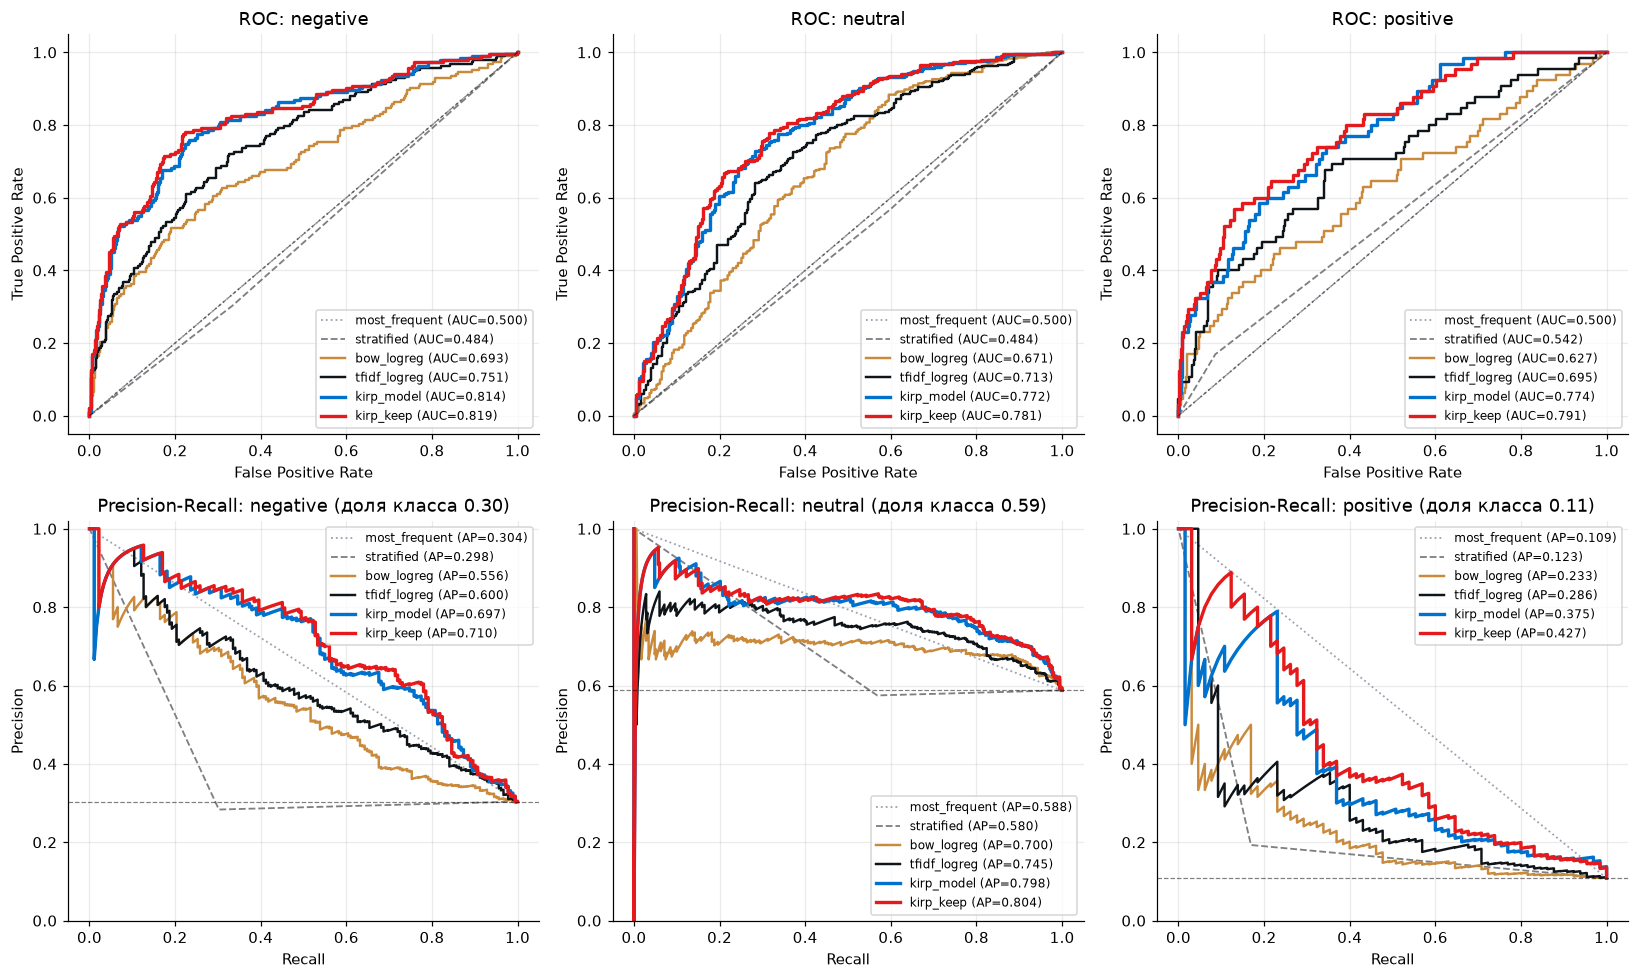

In [53]:
from sklearn.metrics import roc_curve, precision_recall_curve
from sklearn.preprocessing import label_binarize

PLOT_MODELS = BASELINES 
MODEL_STYLE = {
    "most_frequent": dict(color=GREY,   lw=1.2, ls=":"),
    "stratified":    dict(color="#7F7F7F", lw=1.2, ls="--"),
    "bow_logreg":    dict(color=OCHRE,  lw=1.6),
    "tfidf_logreg":  dict(color=BLACK,  lw=1.6),
    "kirp_model":    dict(color=BLUE,   lw=2.2),
    "kirp_keep":     dict(color="#E41A1C", lw=2.2),
}

y_test_bin = label_binarize(y_test, classes=CLASSES)          # (n, 3) из нулей и единиц
proba_all = {}
for name in PLOT_MODELS:
    m = baseline_models[name]
    assert list(m.classes_) == CLASSES, f"порядок классов у {name}: {list(m.classes_)}"
    proba_all[name] = m.predict_proba(X_test)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for j, cls in enumerate(CLASSES):
    ax_roc, ax_pr = axes[0, j], axes[1, j]
    y_bin = y_test_bin[:, j]

    for name in PLOT_MODELS:
        score = proba_all[name][:, j]
        fpr, tpr, _ = roc_curve(y_bin, score)
        prec, rec, _ = precision_recall_curve(y_bin, score)
        roc_val = roc_auc_score(y_bin, score)
        ap_val = average_precision_score(y_bin, score)

        ax_roc.plot(fpr, tpr, label=f"{name} (AUC={roc_val:.3f})", **MODEL_STYLE[name])
        ax_pr.plot(rec, prec, label=f"{name} (AP={ap_val:.3f})", **MODEL_STYLE[name])

    ax_roc.plot([0, 1], [0, 1], color="black", lw=0.8, ls="--", alpha=0.5)
    ax_roc.set_title(f"ROC: {cls}")
    ax_roc.set_xlabel("False Positive Rate")
    ax_roc.set_ylabel("True Positive Rate")
    ax_roc.legend(fontsize=8, loc="lower right")

    base = y_bin.mean()
    ax_pr.axhline(base, color="black", lw=0.8, ls="--", alpha=0.5)
    ax_pr.set_title(f"Precision-Recall: {cls} (доля класса {base:.2f})")
    ax_pr.set_xlabel("Recall")
    ax_pr.set_ylabel("Precision")
    ax_pr.set_ylim(0, 1.02)
    ax_pr.legend(fontsize=8, loc="best")

plt.tight_layout()
plt.show()


In [43]:
# Сравнение kirp_model (стоп-слова удалены) и kirp_keep (важные стоп-слова оставлены) на тесте
rows_cmp = {}
for name in ["kirp_model", "kirp_keep"]:
    pred = baseline_models[name].predict(X_test)
    proba = proba_all[name]
    rows_cmp[name] = {
        "macro_f1": f1_score(y_test, pred, average="macro", zero_division=0),
        "accuracy": accuracy_score(y_test, pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, pred),
        "roc_auc_macro": roc_auc_score(y_test, proba, multi_class="ovr", average="macro"),
        "pr_auc_macro": average_precision_score(y_test_bin, proba, average="macro"),
    }
    for cls in CLASSES:
        yt, yp = (y_test == cls).astype(int), (pred == cls).astype(int)
        rows_cmp[name][f"precision_{cls}"] = precision_score(yt, yp, zero_division=0)
        rows_cmp[name][f"recall_{cls}"] = recall_score(yt, yp, zero_division=0)

pd.DataFrame(rows_cmp).T.round(3)


,macro_f1,accuracy,balanced_accuracy,roc_auc_macro,pr_auc_macro,precision_negative,recall_negative,precision_neutral,recall_neutral,precision_positive,recall_positive
kirp_model,0.57,0.701,0.543,0.787,0.623,0.685,0.538,0.708,0.875,0.667,0.215
kirp_keep,0.58,0.708,0.554,0.797,0.647,0.701,0.555,0.716,0.875,0.600,0.231


## 3. Матрица ошибок лучшей модели

In [44]:
BEST_NAME = baseline_table["macro_f1"].idxmax()

test_pred = baseline_models[BEST_NAME].predict(X_test)

cm = confusion_matrix(y_test, test_pred, labels=CLASSES)
pd.DataFrame(cm, index=[f"факт {c}" for c in CLASSES], columns=[f"предсказано {c}" for c in CLASSES])

,предсказано negative,предсказано neutral,предсказано positive
факт negative,101,78,3
факт neutral,37,308,7
факт positive,6,44,15


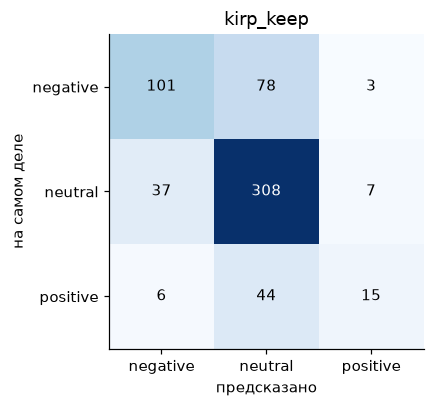

In [45]:
fig, ax = plt.subplots(figsize=(4.4, 3.8))
im = ax.imshow(cm, cmap="Blues")

ax.set_xticks(range(3))
ax.set_xticklabels(CLASSES)
ax.set_yticks(range(3))
ax.set_yticklabels(CLASSES)

ax.set_xlabel("предсказано")
ax.set_ylabel("на самом деле")
ax.set_title(BEST_NAME)
ax.grid(False)

for i in range(3):
    for j in range(3):
        color = "white" if cm[i, j] > cm.max() / 2 else "black"
        ax.text(j, i, cm[i, j], ha="center", va="center", color=color)

plt.tight_layout()
plt.show()


## 4. Разбор ошибок


In [46]:
best_model = baseline_models[BEST_NAME]

# Получаем бинарные прогнозы и полную матрицу вероятностей для X_test
test_pred = best_model.predict(X_test)
proba_test = best_model.predict_proba(X_test)

# Вырезаем именно те строки из task1_df, которые попали в тест по индексам test_idx
test_data_analysis = task1_df.iloc[test_idx].copy()
test_data_analysis["pred"] = test_pred

# Добавляем колонки с вероятностями для каждого из 3-х классов отдельно
for j, cls_name in enumerate(CLASSES):
    test_data_analysis[f"p_{cls_name}"] = proba_test[:, j]

print(f"Таблица для разбора ошибок успешно собрана! Доступно строк для анализа: {len(test_data_analysis)}")

Таблица для разбора ошибок успешно собрана! Доступно строк для анализа: 599


In [47]:
def short(text, n=120):
    # Вспомогательная функция для красивой обрезки длинных реплик ассистента
    return " ".join(text.split())[:n]

def show(df_sub):
    # Функция для вывода диалога на экран в читаемом человеческом виде
    for idx, row in df_sub.iterrows():
        print(f"\n==== Диалог ID: {row.get('dialog_id', 'unknown')} | Факт: {row['reaction']} | Прогноз: {row['pred']} ====")
        
        # Перебираем реплики из turns
        turns = row['turns']
        if isinstance(turns, list):
            # Печатаем первые 4 реплики для контекста, чтобы не забивать экран
            for turn in turns[:4]:
                role = "Пользователь" if turn.get("role") == "user" else "Модель"
                print(f"[{role}]: {short(turn.get('text', ''))}")
        print(f"Вероятности классов -> Neg: {row['p_negative']:.2f} | Neu: {row['p_neutral']:.2f} | Pos: {row['p_positive']:.2f}")
        print("-" * 60)

In [48]:
groups_to_show = {
    "УПУЩЕННЫЙ НЕГАТИВ (Факт: negative, Прогноз: neutral)": (test_data_analysis["reaction"] == "negative") & (test_data_analysis["pred"] == "neutral"),
    "ЛОЖНАЯ ТРЕВОГА (Факт: neutral, Прогноз: negative)": (test_data_analysis["reaction"] == "neutral") & (test_data_analysis["pred"] == "negative"),
    "ИДЕАЛЬНО УГАДАННЫЙ НЕГАТИВ (Уверенность > 70%)": (test_data_analysis["reaction"] == "negative") & (test_data_analysis["p_negative"] > 0.70),
    "ИДЕАЛЬНО УГАДАННЫЙ ПОЗИТИВ (Уверенность > 70%)": (test_data_analysis["reaction"] == "positive") & (test_data_analysis["p_positive"] > 0.70)
}

In [49]:
# Случайным образом выбираем по 2 примера для каждой группы ошибок и выводим их
np.random.seed(42) # фиксируем сид для воспроизводимости отчета
for title, mask in groups_to_show.items():
    sub_df = test_data_analysis[mask]
    print(f"\nГРУППА: {title} (Всего таких ошибок в тесте: {len(sub_df)})")
    if len(sub_df) > 0:
        # Выбираем максимум 2 случайных примера
        sample_size = min(2, len(sub_df))
        show(sub_df.sample(n=sample_size))
    else:
        print("В этой категории ошибок нет! Модель сработала идеально.")



ГРУППА: УПУЩЕННЫЙ НЕГАТИВ (Факт: negative, Прогноз: neutral) (Всего таких ошибок в тесте: 78)

==== Диалог ID: dialog_id    ddcecdee1b9
dialog_id    ddcecdee1b9
Name: 1348, dtype: object | Факт: negative | Прогноз: neutral ====
[Пользователь]: list down all key documents used in Order to cash business process. this time don’t miss anything, verify all informatio
[Модель]: 1. Purchase order: A document issued by the customer to request a specific product or service from the supplier. 2. Sale
[Пользователь]: where is workflow?
[Модель]: Apologies for the oversight. Here is a suggested workflow for the Order-to-Cash process, incorporating the key documents
Вероятности классов -> Neg: 0.15 | Neu: 0.83 | Pos: 0.02
------------------------------------------------------------

==== Диалог ID: dialog_id    d9474cd684d
dialog_id    d9474cd684d
Name: 44, dtype: object | Факт: negative | Прогноз: neutral ====
[Пользователь]: Let’s play a game where you "must logically" contradict everything I sa

## 5. Сохранение моделей

Для скрытого теста модели переобучаем на **всех** размеченных диалогах (dev + test): положительных всего ~300, лишние
данные важны. Параметры и пороги остаются выбранными на кросс-валидации, цифры в таблицах выше получены до переобучения.
Модели сохраняются в `artifacts/` рядом с `solution_utils.py`.

In [50]:
import joblib

In [51]:
ARTIFACTS_DIR = "artifacts"
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

REACTION_ARTIFACTS = {
    "most_frequent": "most_frequent.joblib",
    "stratified": "stratified.joblib",
    "bow_logreg": "bow_logreg.joblib",
    "tfidf_logreg": "tfidf_logreg.joblib",
    "kirp_model": "kirp_model.joblib"

}

for name, model in baseline_models.items():
    if name in REACTION_ARTIFACTS:
        path = os.path.join(ARTIFACTS_DIR, REACTION_ARTIFACTS[name])
        # compress=3 сжимает файлы, чтобы они весили меньше и пролезали в лимиты гитхаба
        joblib.dump(model, path, compress=3)

# Считаем размеры получившихся файлов на диске (в МБ)
sizes = {
    f: round(os.path.getsize(os.path.join(ARTIFACTS_DIR, f)) / 1e6, 1) 
    for f in REACTION_ARTIFACTS.values()
}
print("размеры файлов, МБ:", sizes, " всего:", round(sum(sizes.values()), 1))


размеры файлов, МБ: {'most_frequent.joblib': 0.0, 'stratified.joblib': 0.0, 'bow_logreg.joblib': 1.1, 'tfidf_logreg.joblib': 1.1, 'kirp_model.joblib': 8.5}  всего: 10.7


### 5.1. Проверка: загружаем и тестируем инференс

In [52]:
print("\n--- Запуск проверки загруженных моделей ---")

# Эмулируем функцию init_reaction_models напрямую из файлов
loaded_models = {}
for name, filename in REACTION_ARTIFACTS.items():
    path = os.path.join(ARTIFACTS_DIR, filename)
    loaded_models[name] = joblib.load(path)

# Берем первые 200 диалогов из тестового набора данных X_test
sample_x = X_test.iloc[:200]

for name, model in loaded_models.items():
    # Прямой инференс модели на текстах без сторонних функций-заглушек
    answers = model.predict(sample_x)
    
    # Считаем пропорции ответов, чтобы убедиться, что логистическая регрессия выдает адекватные классы
    print(f"{name:20s} загружена, ответы на 200 диалогах: {pd.Series(answers).value_counts().to_dict()}")


--- Запуск проверки загруженных моделей ---
most_frequent        загружена, ответы на 200 диалогах: {'neutral': 200}
stratified           загружена, ответы на 200 диалогах: {'neutral': 112, 'negative': 68, 'positive': 20}
bow_logreg           загружена, ответы на 200 диалогах: {'neutral': 130, 'negative': 51, 'positive': 19}
tfidf_logreg         загружена, ответы на 200 диалогах: {'neutral': 138, 'negative': 50, 'positive': 12}
kirp_model           загружена, ответы на 200 диалогах: {'neutral': 149, 'negative': 44, 'positive': 7}
